<a href="https://colab.research.google.com/github/rithishacs24-lab/BIS-LAB/blob/main/Particle%20swarm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Starting Particle Swarm Optimization...

Iteration 0: Best Cost = 2051.6000
Iteration 25: Best Cost = 45.6000
Iteration 50: Best Cost = 41.6000
Iteration 75: Best Cost = 39.6000
Iteration 100: Best Cost = 39.6000
Iteration 125: Best Cost = 39.6000
Iteration 150: Best Cost = 37.6000
Iteration 175: Best Cost = 37.6000
Iteration 200: Best Cost = 35.6000
Iteration 225: Best Cost = 35.6000
Iteration 250: Best Cost = 33.6000
Iteration 275: Best Cost = 33.6000

PSO Optimization Completed!

Best Optimization Cost: 33.6
Best Fitness Score: 0.028901734104046242

========== OPTIMIZED WEEKLY SCHEDULE ==========

      Day                 Morning                Evening                   Night
   Monday  Employee_5, Employee_6 Employee_2, Employee_9  Employee_1, Employee_3
  Tuesday  Employee_7, Employee_8 Employee_2, Employee_9 Employee_3, Employee_10
Wednesday  Employee_9, Employee_4 Employee_7, Employee_1 Employee_10, Employee_8
 Thursday  Employee_7, Employee_4 Employee_2, Employee_1  Employee_8

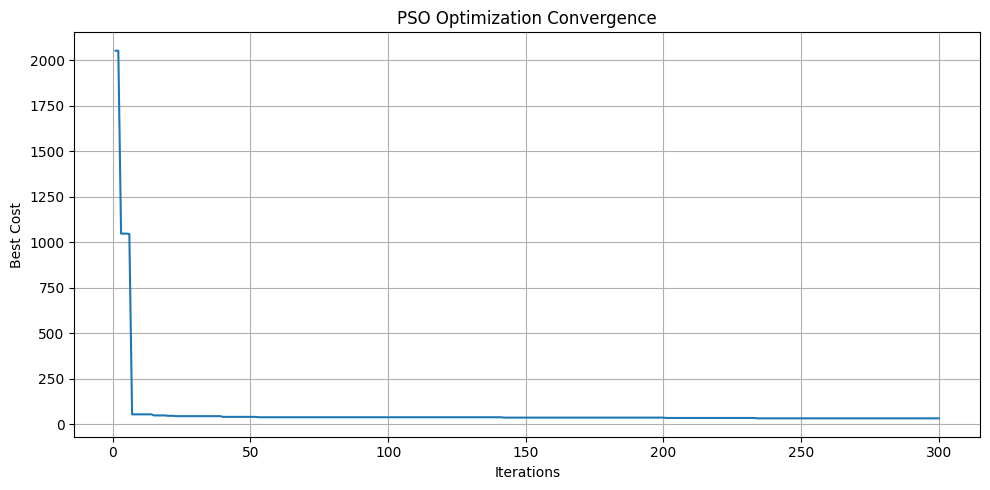

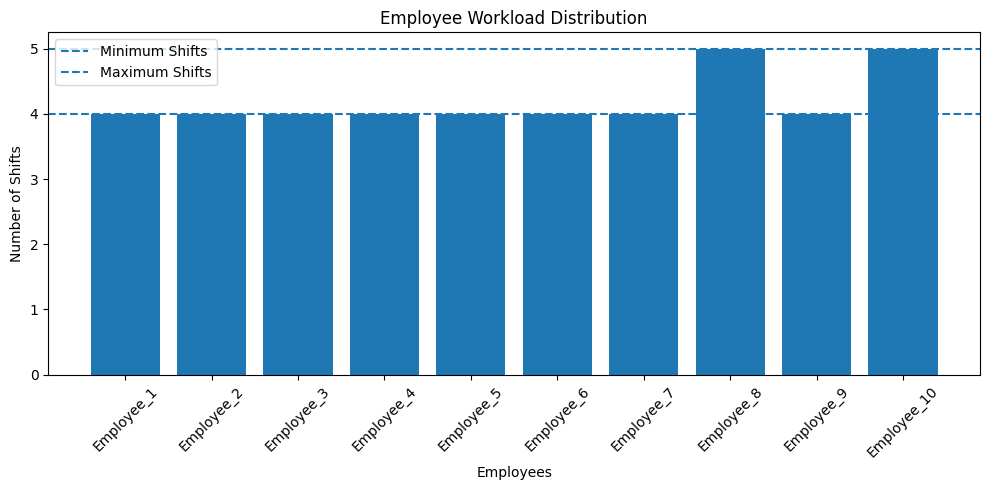

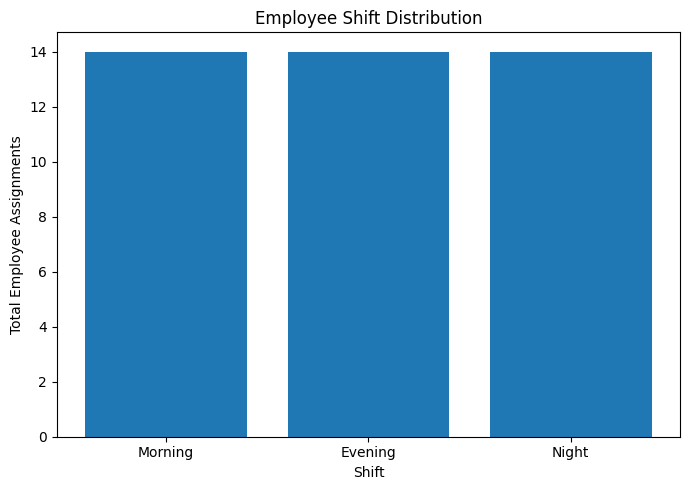


Excel report generated successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# ============================================================
# PARTICLE SWARM OPTIMIZATION (PSO)
# EMPLOYEE SHIFT SCHEDULING OPTIMIZATION
# GOOGLE COLAB IMPLEMENTATION
# ============================================================

import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt

from scipy.optimize import linear_sum_assignment
from google.colab import files

# ------------------------------------------------------------
# 1. PROBLEM CONFIGURATION
# ------------------------------------------------------------

np.random.seed(42)
random.seed(42)

employees = [
    "Employee_1", "Employee_2", "Employee_3",
    "Employee_4", "Employee_5", "Employee_6",
    "Employee_7", "Employee_8", "Employee_9",
    "Employee_10"
]

days = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

shifts = ["Morning", "Evening", "Night"]

EMPLOYEE_COUNT = len(employees)
DAYS_COUNT = len(days)
SHIFTS_COUNT = len(shifts)

EMPLOYEES_PER_SHIFT = 2
SLOTS_PER_DAY = SHIFTS_COUNT * EMPLOYEES_PER_SHIFT

MIN_SHIFTS = 4
MAX_SHIFTS = 5

# ------------------------------------------------------------
# 2. PSO PARAMETERS
# ------------------------------------------------------------

NUM_PARTICLES = 60
MAX_ITERATIONS = 300

W = 0.7          # Inertia weight
C1 = 1.5         # Cognitive coefficient
C2 = 1.5         # Social coefficient

VELOCITY_LIMIT = 1.0
POSITION_LIMIT = 5.0

# ------------------------------------------------------------
# 3. EMPLOYEE SHIFT PREFERENCES
# ------------------------------------------------------------

preferences = {
    "Employee_1": ["Morning"],
    "Employee_2": ["Evening"],
    "Employee_3": ["Night"],
    "Employee_4": ["Morning", "Evening"],
    "Employee_5": ["Evening"],
    "Employee_6": ["Night"],
    "Employee_7": ["Morning"],
    "Employee_8": ["Morning", "Night"],
    "Employee_9": ["Evening"],
    "Employee_10": ["Night", "Evening"]
}

# ------------------------------------------------------------
# 4. PARTICLE REPRESENTATION
# ------------------------------------------------------------

# Each particle contains a score for assigning each employee
# to each of the six daily shift positions.
#
# Shape:
# (7 days, 6 shift positions, 10 employees)
#
# The Hungarian algorithm converts these scores into
# six unique employee assignments per day.

PARTICLE_SHAPE = (
    DAYS_COUNT,
    SLOTS_PER_DAY,
    EMPLOYEE_COUNT
)

# ------------------------------------------------------------
# 5. DECODE PARTICLE INTO EMPLOYEE SCHEDULE
# ------------------------------------------------------------

def decode_particle(position):

    schedule = np.zeros(
        (DAYS_COUNT, SLOTS_PER_DAY),
        dtype=int
    )

    for day in range(DAYS_COUNT):

        score_matrix = position[day]

        # Assign six unique employees to six shift positions
        rows, cols = linear_sum_assignment(
            -score_matrix
        )

        schedule[day, rows] = cols

    return schedule


# ------------------------------------------------------------
# 6. FITNESS / COST FUNCTION
# ------------------------------------------------------------

def calculate_cost(position):

    schedule = decode_particle(position)

    workload = np.zeros(EMPLOYEE_COUNT, dtype=int)

    preference_penalty = 0

    # Calculate employee workload and preference penalties
    for day in range(DAYS_COUNT):

        for slot in range(SLOTS_PER_DAY):

            employee_index = schedule[day, slot]

            shift_index = slot // EMPLOYEES_PER_SHIFT

            workload[employee_index] += 1

            employee_name = employees[employee_index]
            shift_name = shifts[shift_index]

            if shift_name not in preferences[employee_name]:
                preference_penalty += 1

    # Penalize employees outside 4-5 shifts
    workload_penalty = np.sum(
        np.maximum(0, MIN_SHIFTS - workload) ** 2
        +
        np.maximum(0, workload - MAX_SHIFTS) ** 2
    )

    # Encourage fair workload distribution
    average_workload = (
        DAYS_COUNT * SLOTS_PER_DAY / EMPLOYEE_COUNT
    )

    fairness_penalty = np.sum(
        (workload - average_workload) ** 2
    )

    # Total optimization cost
    total_cost = (
        1000 * workload_penalty
        + 2 * preference_penalty
        + 1 * fairness_penalty
    )

    return total_cost


# ------------------------------------------------------------
# 7. INITIALIZE PARTICLES
# ------------------------------------------------------------

positions = np.random.uniform(
    -1, 1,
    size=(NUM_PARTICLES,) + PARTICLE_SHAPE
)

velocities = np.random.uniform(
    -0.5, 0.5,
    size=(NUM_PARTICLES,) + PARTICLE_SHAPE
)

# Personal best positions
pbest_positions = positions.copy()

pbest_costs = np.array([
    calculate_cost(position)
    for position in positions
])

# Global best position
best_particle_index = np.argmin(pbest_costs)

gbest_position = pbest_positions[
    best_particle_index
].copy()

gbest_cost = pbest_costs[
    best_particle_index
]

# Store optimization history
cost_history = []

# ------------------------------------------------------------
# 8. PARTICLE SWARM OPTIMIZATION
# ------------------------------------------------------------

print("Starting Particle Swarm Optimization...\n")

for iteration in range(MAX_ITERATIONS):

    for i in range(NUM_PARTICLES):

        # Generate random coefficients
        r1 = np.random.random(PARTICLE_SHAPE)
        r2 = np.random.random(PARTICLE_SHAPE)

        # Velocity update equation
        velocities[i] = (
            W * velocities[i]
            +
            C1 * r1 * (
                pbest_positions[i] - positions[i]
            )
            +
            C2 * r2 * (
                gbest_position - positions[i]
            )
        )

        # Limit velocity
        velocities[i] = np.clip(
            velocities[i],
            -VELOCITY_LIMIT,
            VELOCITY_LIMIT
        )

        # Position update equation
        positions[i] = (
            positions[i] + velocities[i]
        )

        # Keep position within boundaries
        positions[i] = np.clip(
            positions[i],
            -POSITION_LIMIT,
            POSITION_LIMIT
        )

        # Calculate new cost
        current_cost = calculate_cost(positions[i])

        # Update personal best
        if current_cost < pbest_costs[i]:

            pbest_costs[i] = current_cost

            pbest_positions[i] = positions[i].copy()

        # Update global best
        if current_cost < gbest_cost:

            gbest_cost = current_cost

            gbest_position = positions[i].copy()

    cost_history.append(gbest_cost)

    if iteration % 25 == 0:

        print(
            f"Iteration {iteration}: "
            f"Best Cost = {gbest_cost:.4f}"
        )

print("\nPSO Optimization Completed!")

# ------------------------------------------------------------
# 9. GET BEST EMPLOYEE SCHEDULE
# ------------------------------------------------------------

best_schedule = decode_particle(gbest_position)

best_fitness = 1 / (1 + gbest_cost)

print("\nBest Optimization Cost:", gbest_cost)
print("Best Fitness Score:", best_fitness)

# ------------------------------------------------------------
# 10. DISPLAY WEEKLY EMPLOYEE SCHEDULE
# ------------------------------------------------------------

schedule_data = []

for day in range(DAYS_COUNT):

    row = {"Day": days[day]}

    for shift_index in range(SHIFTS_COUNT):

        start = shift_index * EMPLOYEES_PER_SHIFT

        assigned_employees = [
            employees[best_schedule[day, start + j]]
            for j in range(EMPLOYEES_PER_SHIFT)
        ]

        row[shifts[shift_index]] = ", ".join(
            assigned_employees
        )

    schedule_data.append(row)

schedule_df = pd.DataFrame(schedule_data)

print("\n========== OPTIMIZED WEEKLY SCHEDULE ==========\n")

print(schedule_df.to_string(index=False))

# ------------------------------------------------------------
# 11. EMPLOYEE WORKLOAD ANALYSIS
# ------------------------------------------------------------

workload = np.bincount(
    best_schedule.flatten(),
    minlength=EMPLOYEE_COUNT
)

workload_df = pd.DataFrame({
    "Employee": employees,
    "Total Shifts": workload,
    "Minimum Required": MIN_SHIFTS,
    "Maximum Allowed": MAX_SHIFTS
})

print("\n========== EMPLOYEE WORKLOAD ==========\n")

print(workload_df.to_string(index=False))

# ------------------------------------------------------------
# 12. SCHEDULE VALIDATION
# ------------------------------------------------------------

def validate_schedule(schedule):

    valid = True

    # Check daily duplicate assignments
    for day in range(DAYS_COUNT):

        assigned = schedule[day]

        if len(set(assigned)) != SLOTS_PER_DAY:

            print(
                "ERROR: Duplicate employee assignment on",
                days[day]
            )

            valid = False

    # Check workload limits
    employee_workload = np.bincount(
        schedule.flatten(),
        minlength=EMPLOYEE_COUNT
    )

    for i, count in enumerate(employee_workload):

        if count < MIN_SHIFTS or count > MAX_SHIFTS:

            print(
                f"WARNING: {employees[i]} "
                f"has {count} shifts."
            )

            valid = False

    if valid:

        print(
            "SUCCESS: All hard scheduling constraints satisfied!"
        )

    else:

        print(
            "Some workload constraints were not satisfied."
        )

    return valid


print("\n========== VALIDATION RESULTS ==========\n")

validation_result = validate_schedule(best_schedule)

# ------------------------------------------------------------
# 13. FITNESS CONVERGENCE GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, MAX_ITERATIONS + 1),
    cost_history
)

plt.title("PSO Optimization Convergence")
plt.xlabel("Iterations")
plt.ylabel("Best Cost")
plt.grid(True)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 14. EMPLOYEE WORKLOAD GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(employees, workload)

plt.axhline(
    MIN_SHIFTS,
    linestyle="--",
    label="Minimum Shifts"
)

plt.axhline(
    MAX_SHIFTS,
    linestyle="--",
    label="Maximum Shifts"
)

plt.title("Employee Workload Distribution")
plt.xlabel("Employees")
plt.ylabel("Number of Shifts")

plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 15. SHIFT DISTRIBUTION GRAPH
# ------------------------------------------------------------

shift_counts = []

for shift_index in range(SHIFTS_COUNT):

    count = np.sum(
        best_schedule[:, shift_index * 2:
                      (shift_index + 1) * 2] >= 0
    )

    shift_counts.append(count)

plt.figure(figsize=(7, 5))

plt.bar(shifts, shift_counts)

plt.title("Employee Shift Distribution")
plt.xlabel("Shift")
plt.ylabel("Total Employee Assignments")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 16. EXPORT RESULTS TO EXCEL
# ------------------------------------------------------------

with pd.ExcelWriter(
    "PSO_Employee_Shift_Schedule.xlsx"
) as writer:

    schedule_df.to_excel(
        writer,
        sheet_name="Weekly Schedule",
        index=False
    )

    workload_df.to_excel(
        writer,
        sheet_name="Employee Workload",
        index=False
    )

    convergence_df = pd.DataFrame({
        "Iteration": range(1, MAX_ITERATIONS + 1),
        "Best Cost": cost_history
    })

    convergence_df.to_excel(
        writer,
        sheet_name="PSO Convergence",
        index=False
    )

print("\nExcel report generated successfully!")

# Download Excel file
files.download(
    "PSO_Employee_Shift_Schedule.xlsx"
)